# XAI-STIM

This notebook demonstrates the checkpoint-based XAI-STIM workflow on `sample_data.npz` and `sample_meta.csv` in four steps:

1. import and inspect the raw trajectory;
2. resample and filter the signals;
3. divide every depth into one-second windows and run inference;
4. generate one-dimensional Grad-CAM explanations.

Figures are saved under `results/main_figures/`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
PREPARATION = ROOT / 'modules' / '01_data_preparation'
XAI = ROOT / 'modules' / '02_XAI-STIM'
sys.path.insert(0, str(PREPARATION))
sys.path.insert(0, str(XAI))

from processing import (
    TARGET_FS,
    WINDOW,
    create_filter_coefficients,
    filter_signals,
    load_matrix,
    resample_signals,
)
from inference import MODELS, inference
from gradcam1D import gradcam1D, plot_gradcam

FIGURES = ROOT / 'results' / 'main_figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 300, 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Data import

Load the sample MER trajectory.

Loaded 11 recordings with shape (11, 100000) at 20,000 Hz.


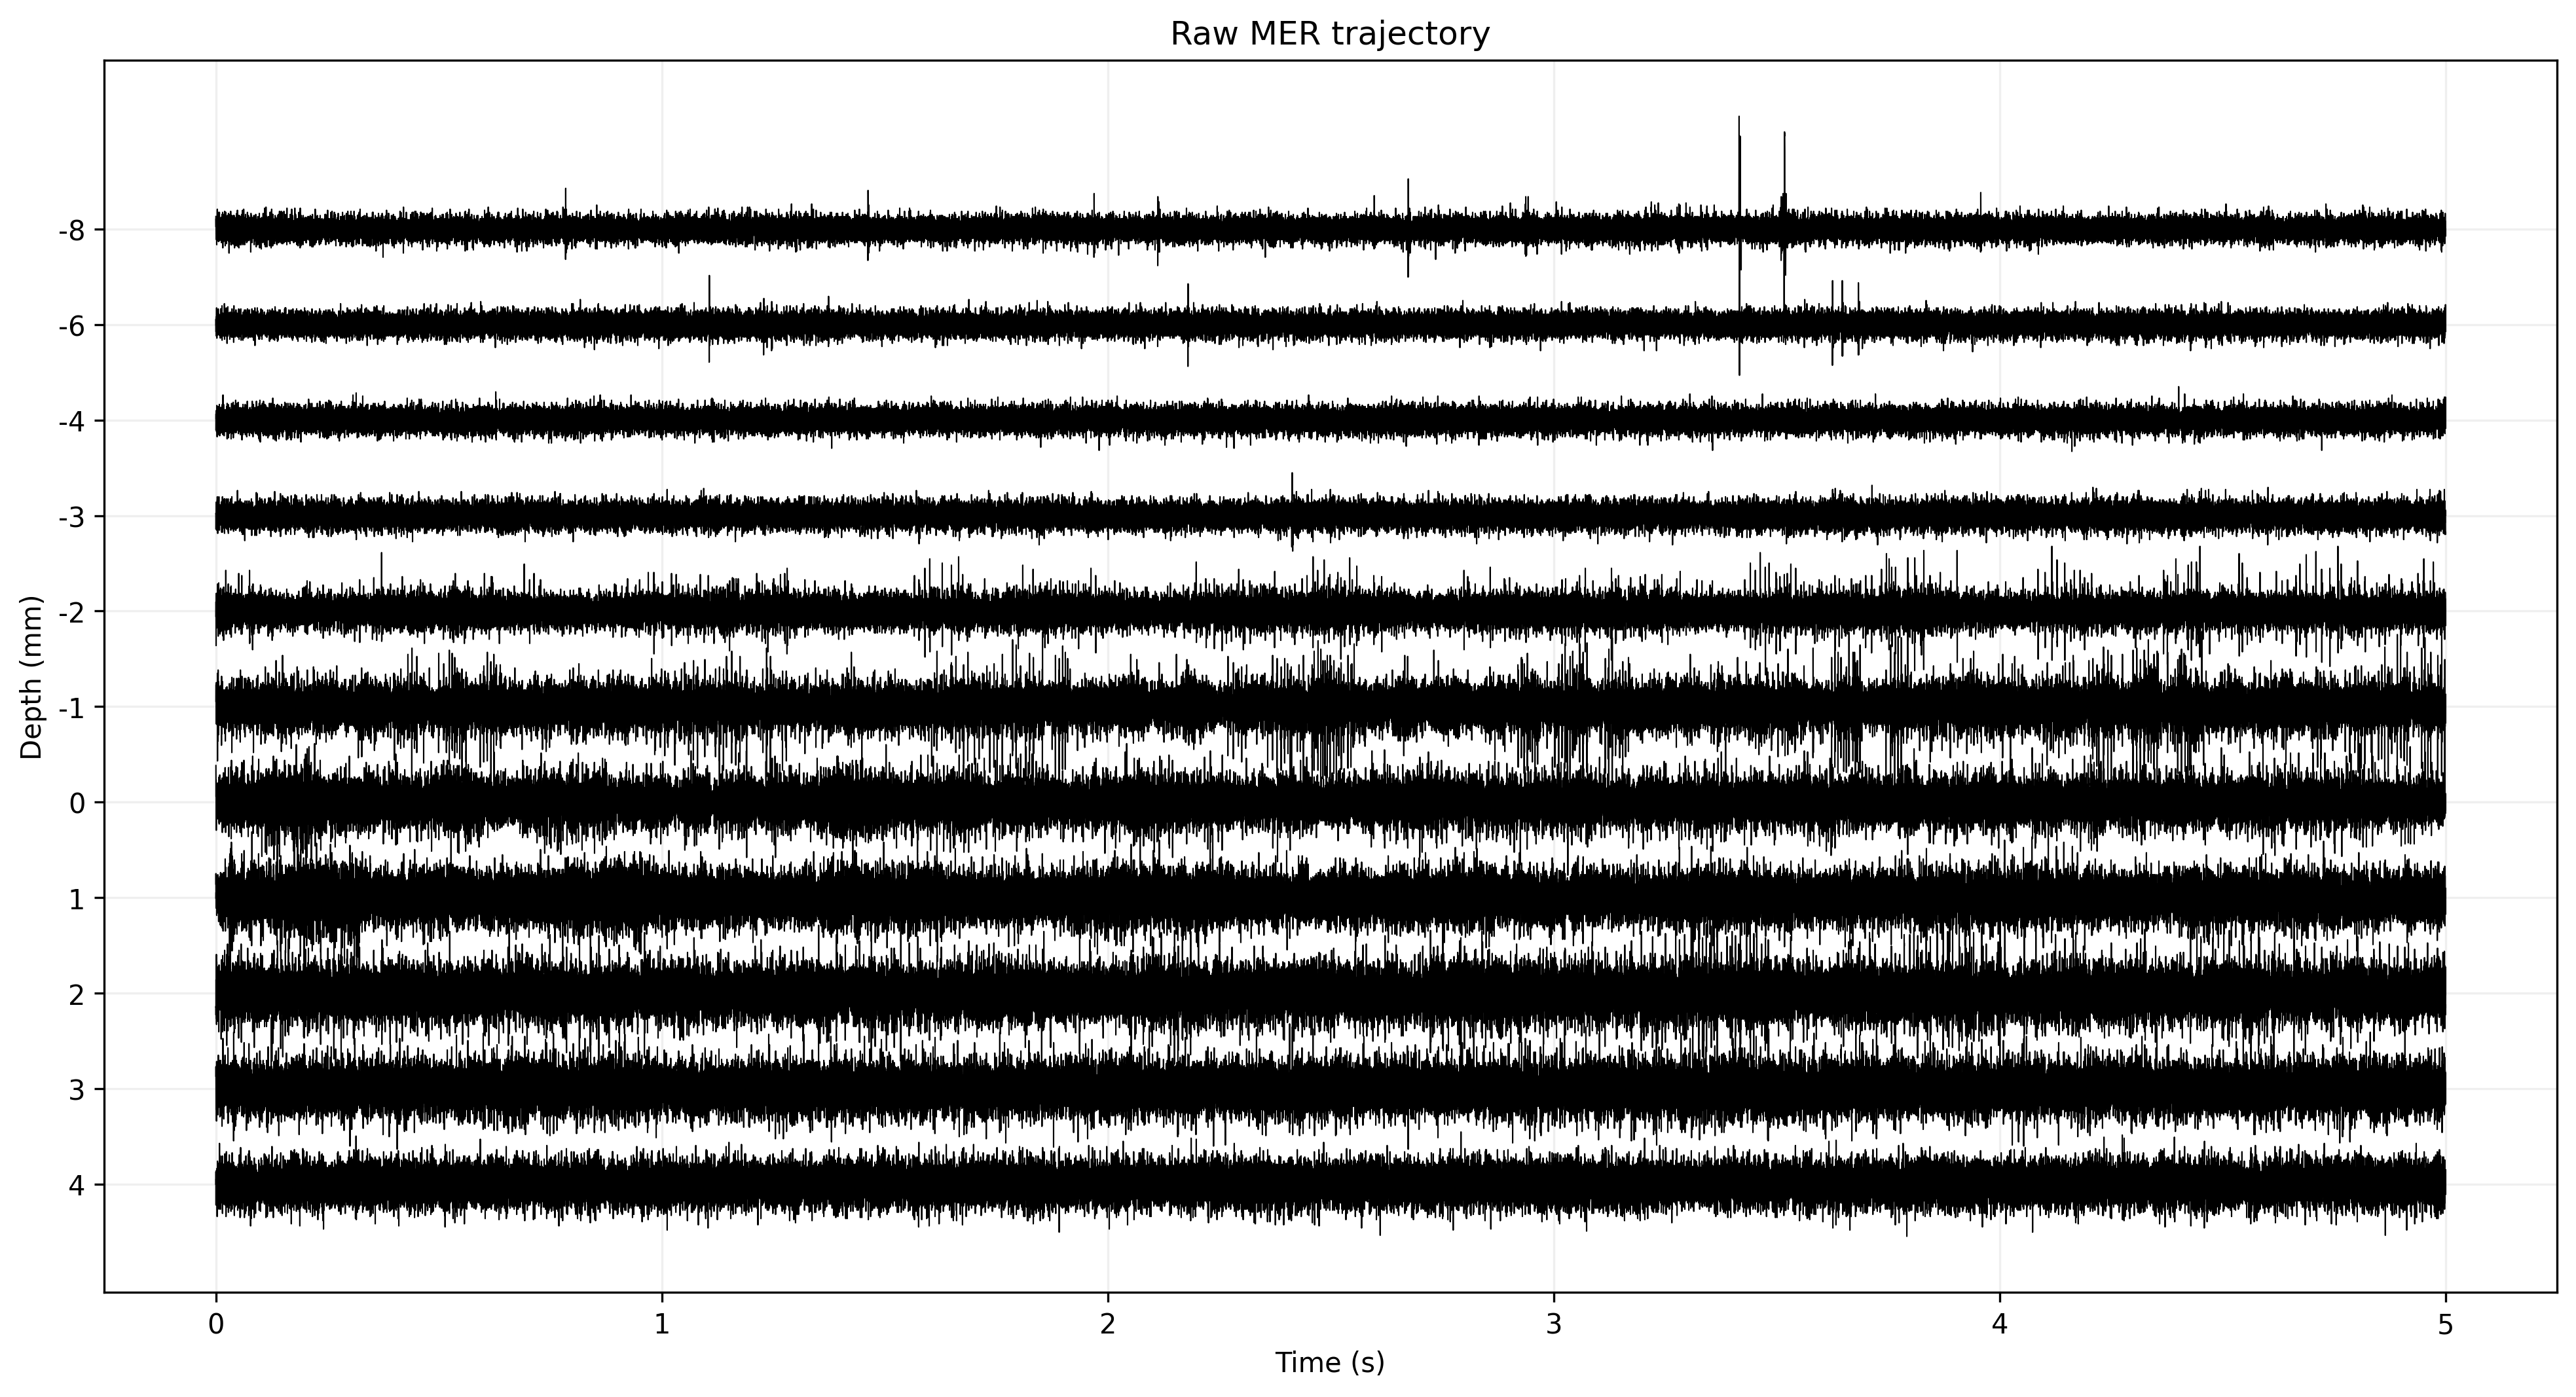

In [2]:
raw = load_matrix(ROOT / 'sample_data.npz')
metadata = pd.read_csv(ROOT / 'sample_meta.csv', dtype={'patient': str})

original_fs = 20_000  # NeuroSet sampling frequency
order = np.argsort(metadata['depth'].to_numpy())
display_samples = int(metadata['length'].min())
time_raw = np.arange(display_samples) / original_fs
raw_scale = np.percentile(np.abs(raw[:, :display_samples]), 99)

print(f'Loaded {len(raw)} recordings with shape {raw.shape} at {original_fs:,} Hz.')

fig, ax = plt.subplots(figsize=(13, 7), layout='constrained')
for position, row_index in enumerate(order):
    trace = raw[row_index, :display_samples]
    ax.plot(time_raw, trace / raw_scale * 0.35 - position, color='black', linewidth=0.5)
ax.set(
    yticks=-np.arange(len(order)),
    yticklabels=(metadata.iloc[order]['depth'] / 1000).map('{:g}'.format),
    xlabel='Time (s)',
    ylabel='Depth (mm)',
    title='Raw MER trajectory',
)
fig.savefig(FIGURES / '01_raw_signals.png', dpi=300, bbox_inches='tight')
plt.show()

## 2. Processing

Resample each recording to the model frequency of 10 kHz, then apply the 200 Hz high-pass filter and notch filters at the 50 Hz harmonics.

Resampled to 10,000 Hz and processed 11 recordings.


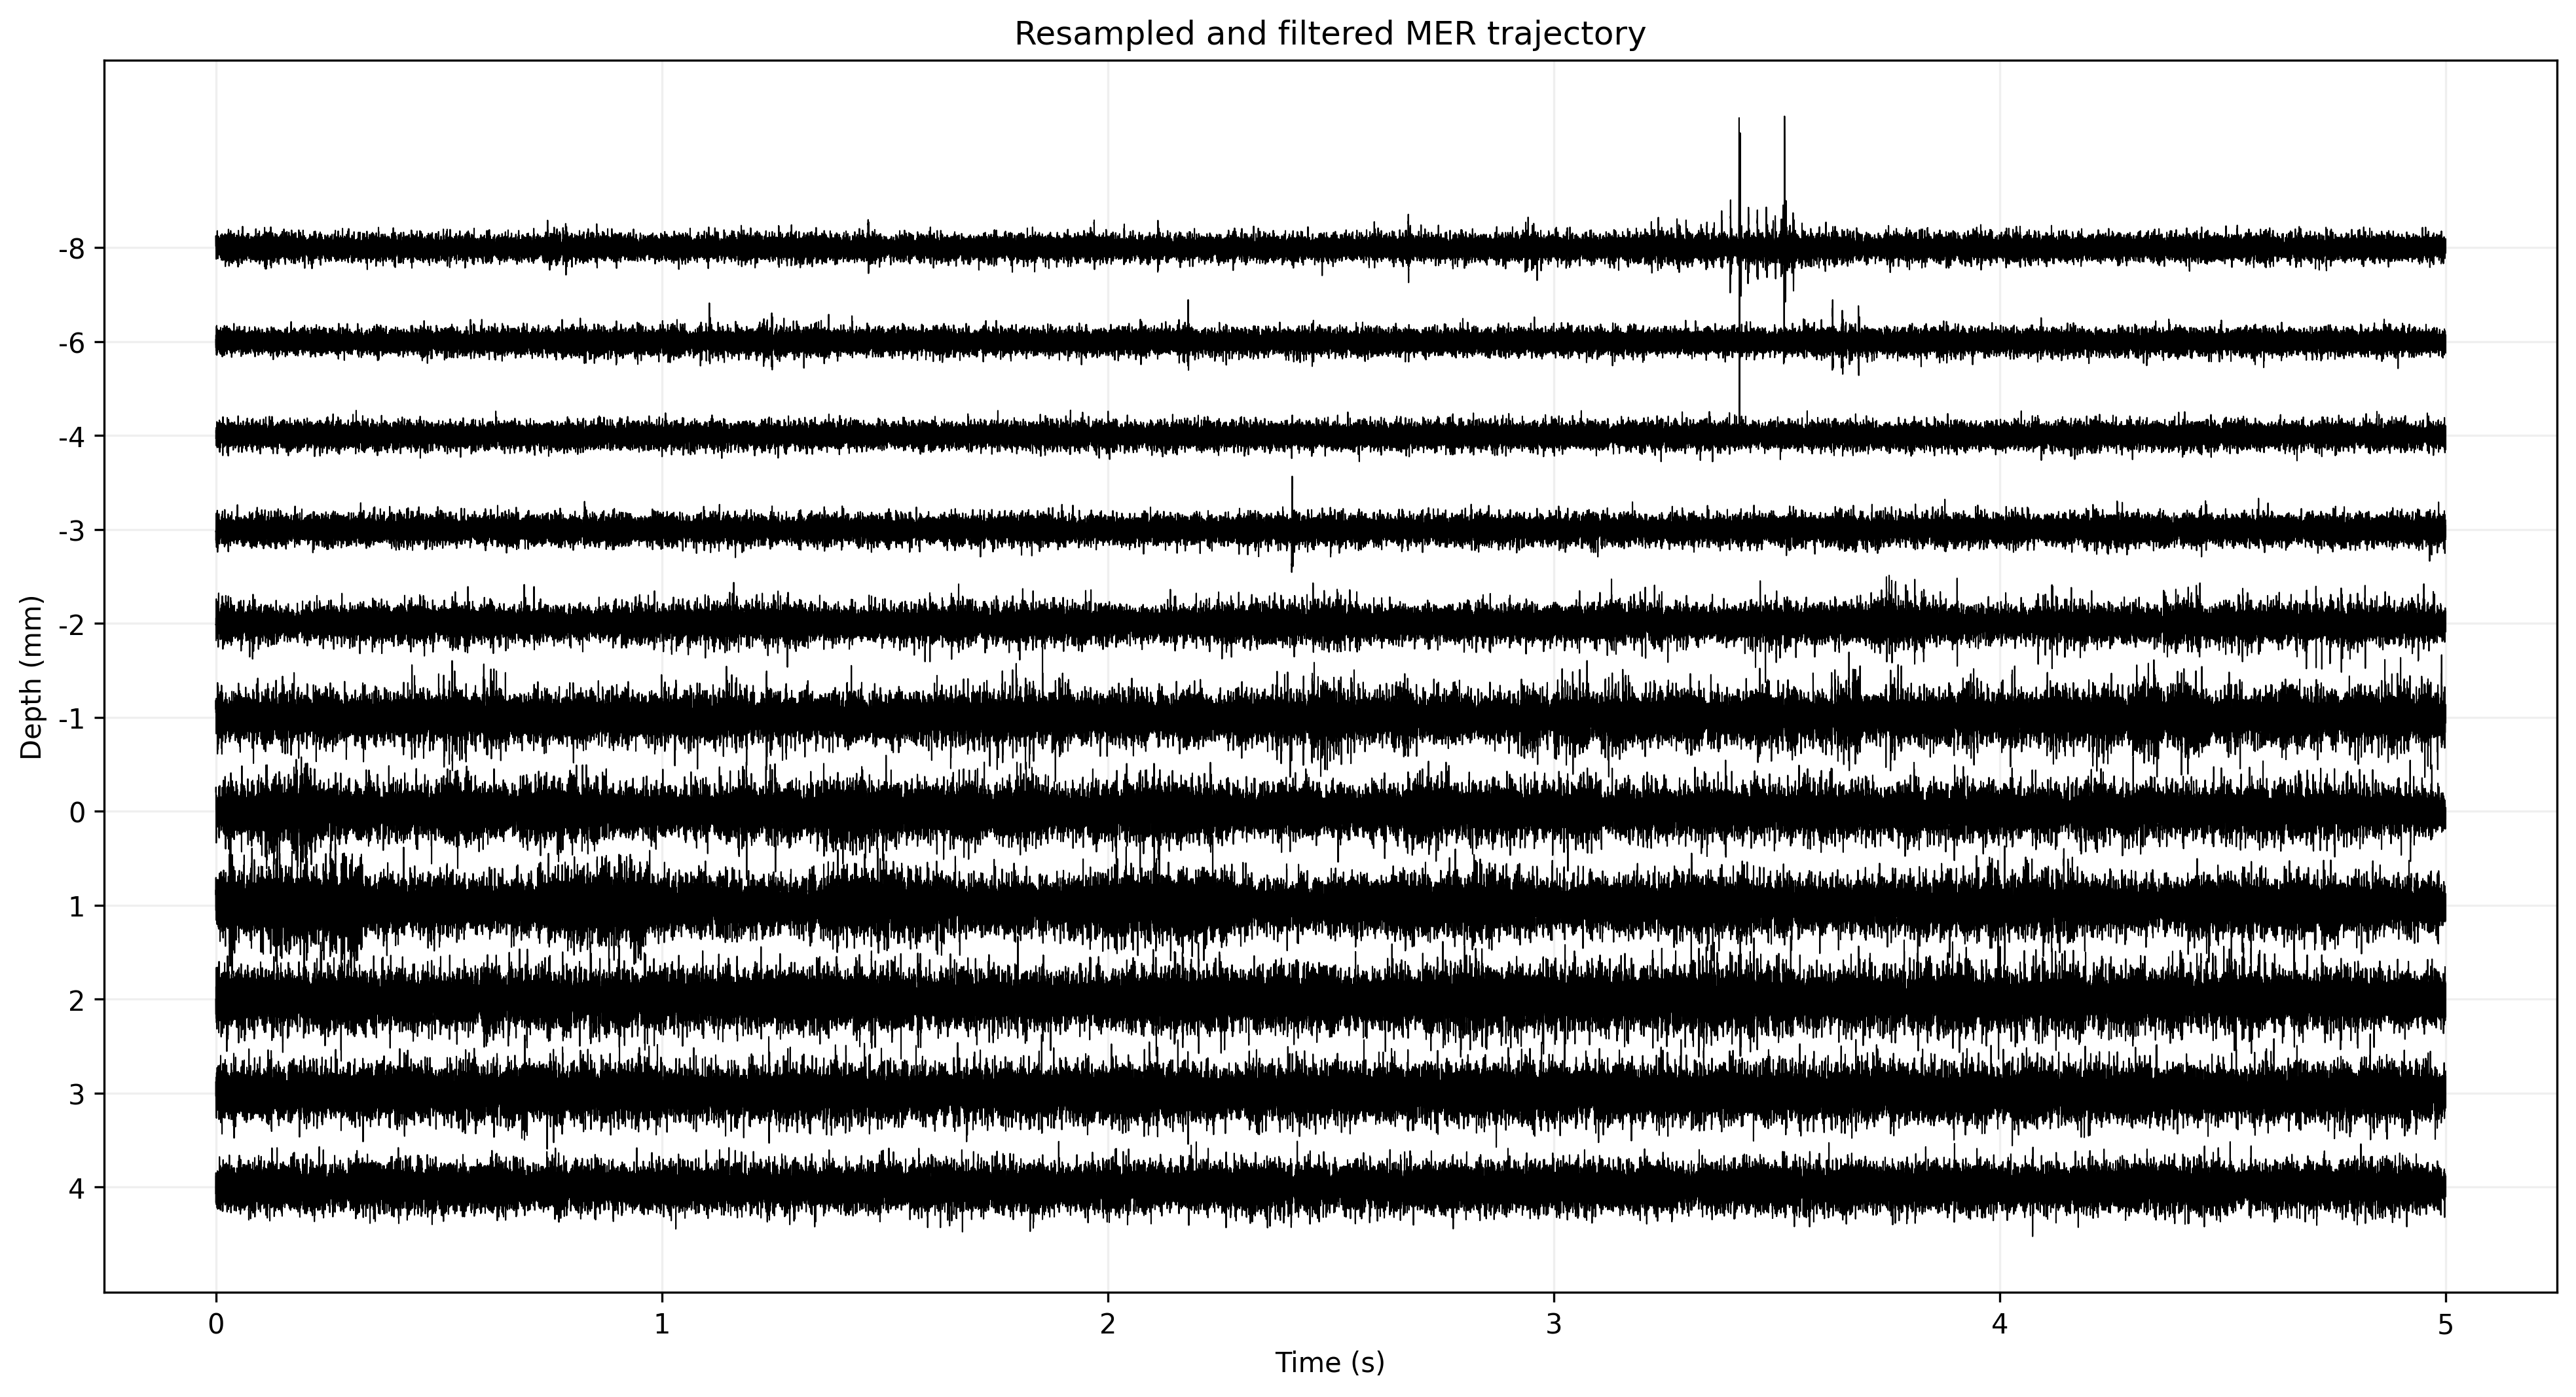

In [3]:
resampled, resampled_metadata = resample_signals(raw, metadata, original_fs)
coefficients = create_filter_coefficients()
processed = np.zeros_like(resampled)
for row_index, row in enumerate(resampled):
    length = int(resampled_metadata.iloc[row_index]['length'])
    processed[row_index, :length] = filter_signals(row[:length], coefficients)

display_samples = int(resampled_metadata['length'].min())
time_processed = np.arange(display_samples) / TARGET_FS
processed_scale = np.percentile(np.abs(processed[:, :display_samples]), 99)

print(f'Resampled to {TARGET_FS:,} Hz and processed {len(processed)} recordings.')

fig, ax = plt.subplots(figsize=(13, 7), layout='constrained')
for position, row_index in enumerate(order):
    trace = processed[row_index, :display_samples]
    ax.plot(time_processed, trace / processed_scale * 0.35 - position, color='black', linewidth=0.5)
ax.set(
    yticks=-np.arange(len(order)),
    yticklabels=(metadata.iloc[order]['depth'] / 1000).map('{:g}'.format),
    xlabel='Time (s)',
    ylabel='Depth (mm)',
    title='Resampled and filtered MER trajectory',
)
fig.savefig(FIGURES / '02_processed_signals.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Inference

Pass one complete resampled recording at a time to `inference`. The function divides it into one-second windows using a user-settable overlap, applies the model preprocessing independently to every window, and runs the released all-in-one checkpoint. The scatter plot shows the distribution of window-level STN probabilities at each depth; the black line is the mean STN probability for that depth.

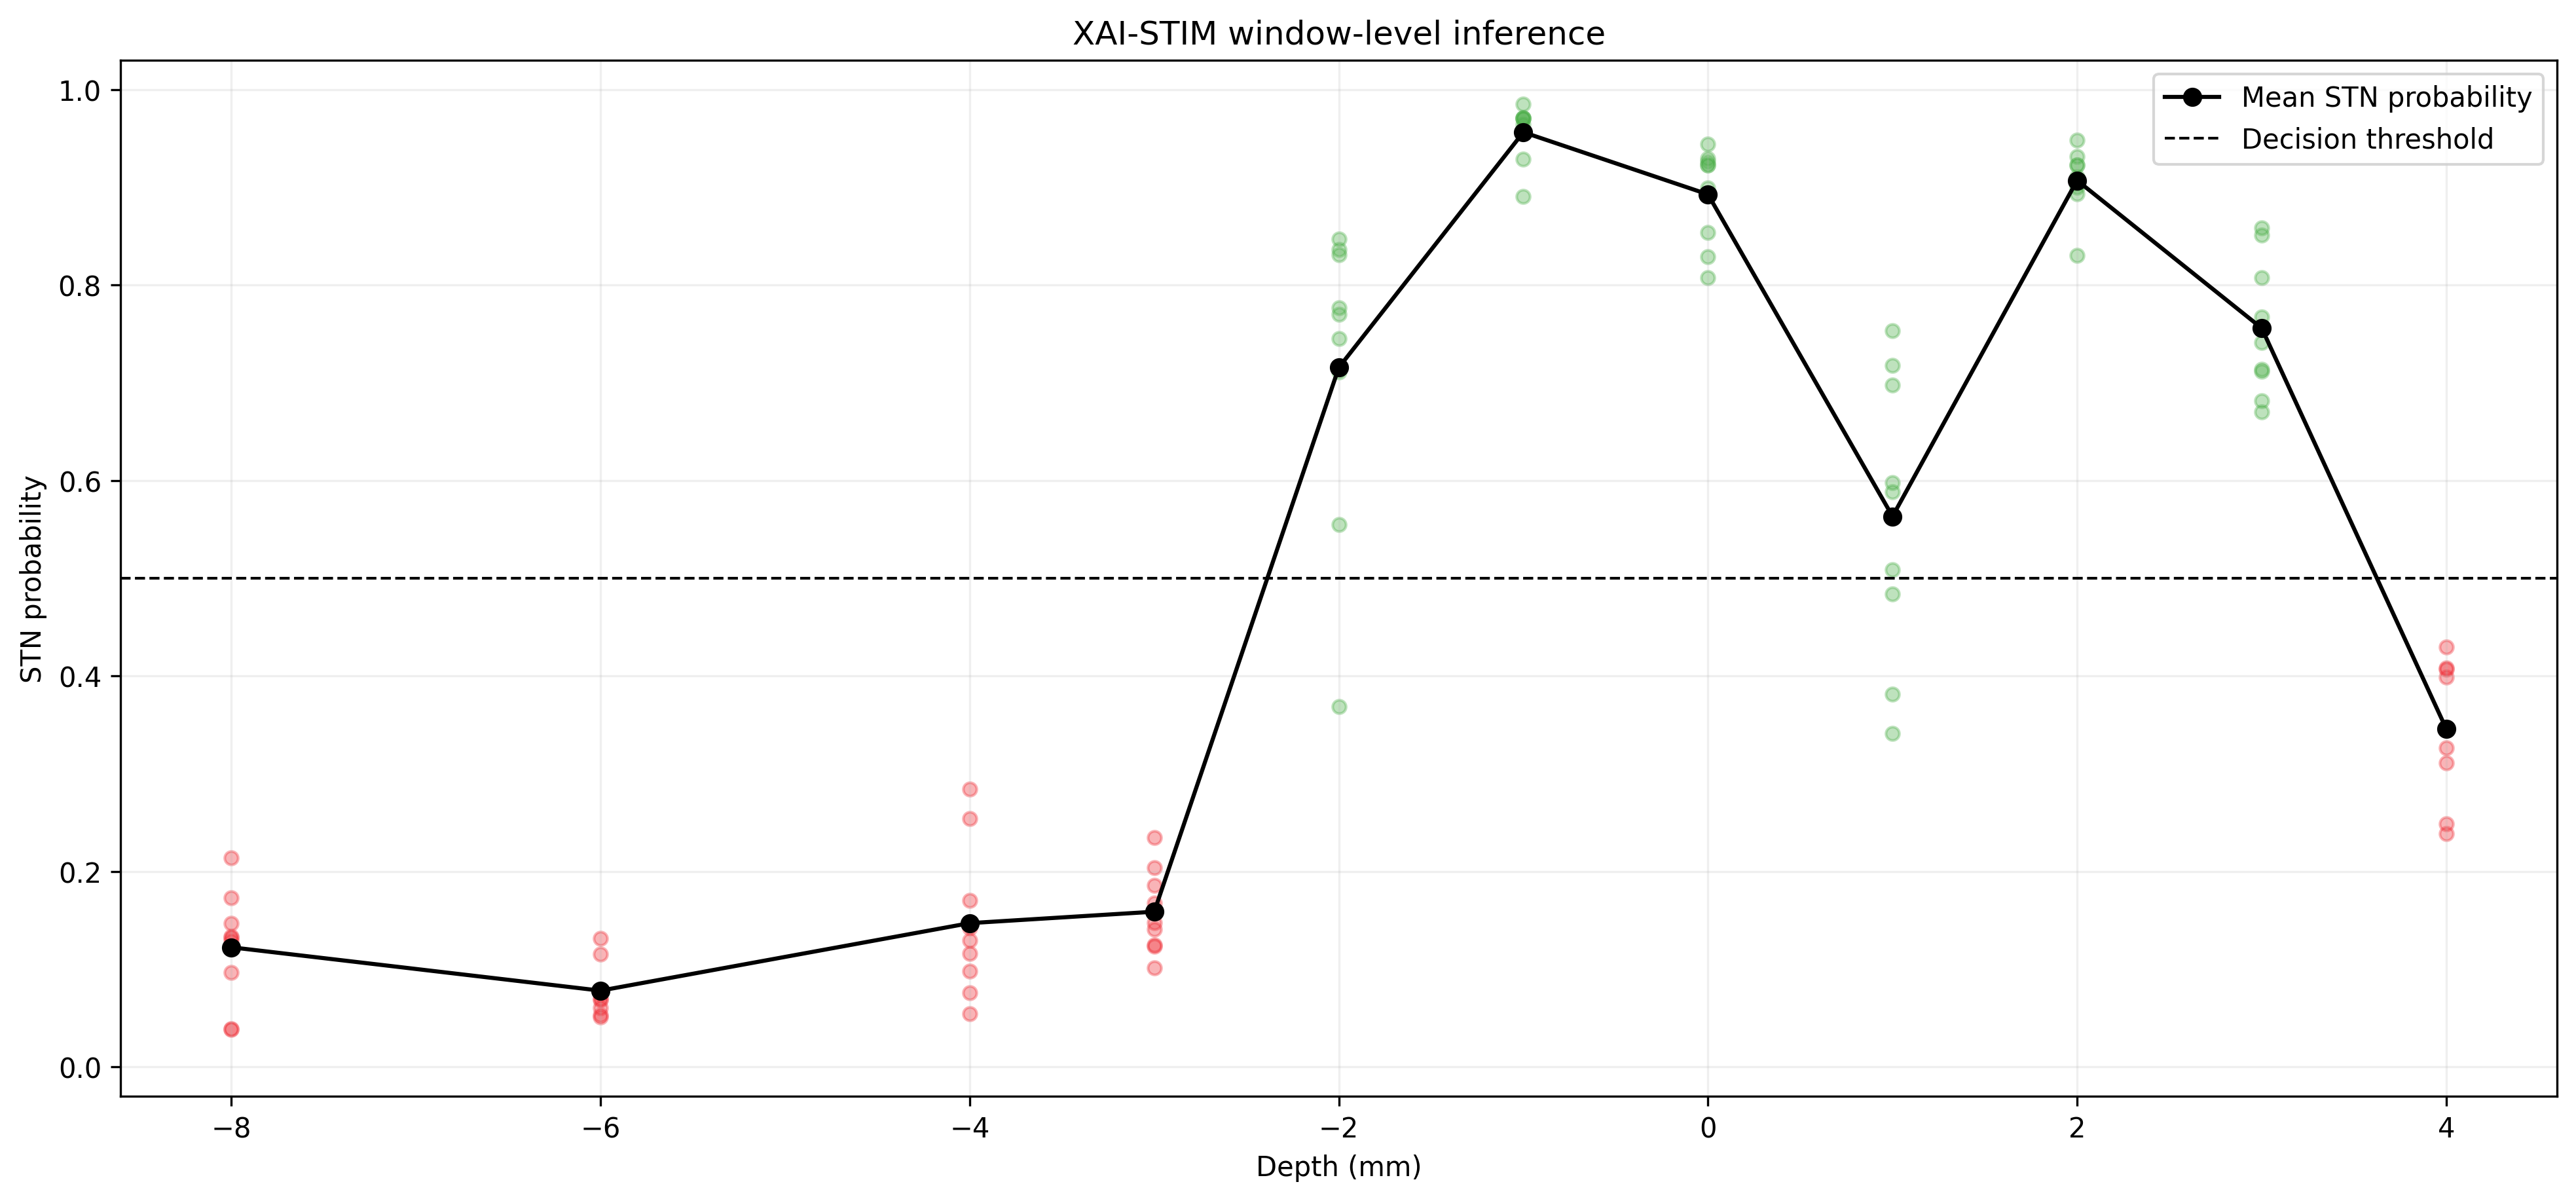

In [5]:
WINDOW_OVERLAP = 0.50  # Fraction shared by consecutive one-second windows.
prediction_tables = []

for row_index, row in enumerate(resampled):
    recording = resampled_metadata.iloc[row_index]
    signal_length = int(recording['length'])
    probabilities, starts = inference(
        row[:signal_length],
        model_path=MODELS / 'all_in_one.pt',
        overlap=WINDOW_OVERLAP,
        return_window_starts=True,
    )
    prediction_tables.append(pd.DataFrame({
        'depth': recording['depth'],
        'class': recording['class'],
        'softmax0': probabilities[:, 0],
        'softmax1': probabilities[:, 1],
        'prediction': probabilities.argmax(axis=1),
    }))

prediction_table = pd.concat(prediction_tables, ignore_index=True)

depth_order = np.sort(prediction_table['depth'].unique())
fig, ax = plt.subplots(figsize=(13, 6), layout='constrained')
for depth in depth_order:
    rows = prediction_table[prediction_table['depth'] == depth]
    color = '#4daf4a' if int(rows['class'].iloc[0]) == 1 else '#ef3038'
    ax.scatter( 
        np.full(len(rows), depth / 1000),
        rows['softmax1'],
        color=color,
        alpha=0.36,
        s=24,
    )

means = prediction_table.groupby('depth', sort=True)['softmax1'].mean()
ax.plot(
    means.index / 1000,
    means.values,
    color='black',
    marker='o',
    linewidth=1.5,
    label='Mean STN probability',
)
ax.axhline(0.5, color='black', linestyle='--', linewidth=1, label='Decision threshold')
ax.set(
    ylim=(-0.03, 1.03),
    xlabel='Depth (mm)',
    ylabel='STN probability',
    title='XAI-STIM window-level inference',
)
ax.legend()
fig.savefig(FIGURES / '03_inference.png', dpi=300, bbox_inches='tight')
plt.show()

## 4. Explanation generation

Generate class-1 Grad-CAM explanations for the complete trajectory. The existing visualization overlays probability-scaled relevance on each signal and reports its mean STN probability.

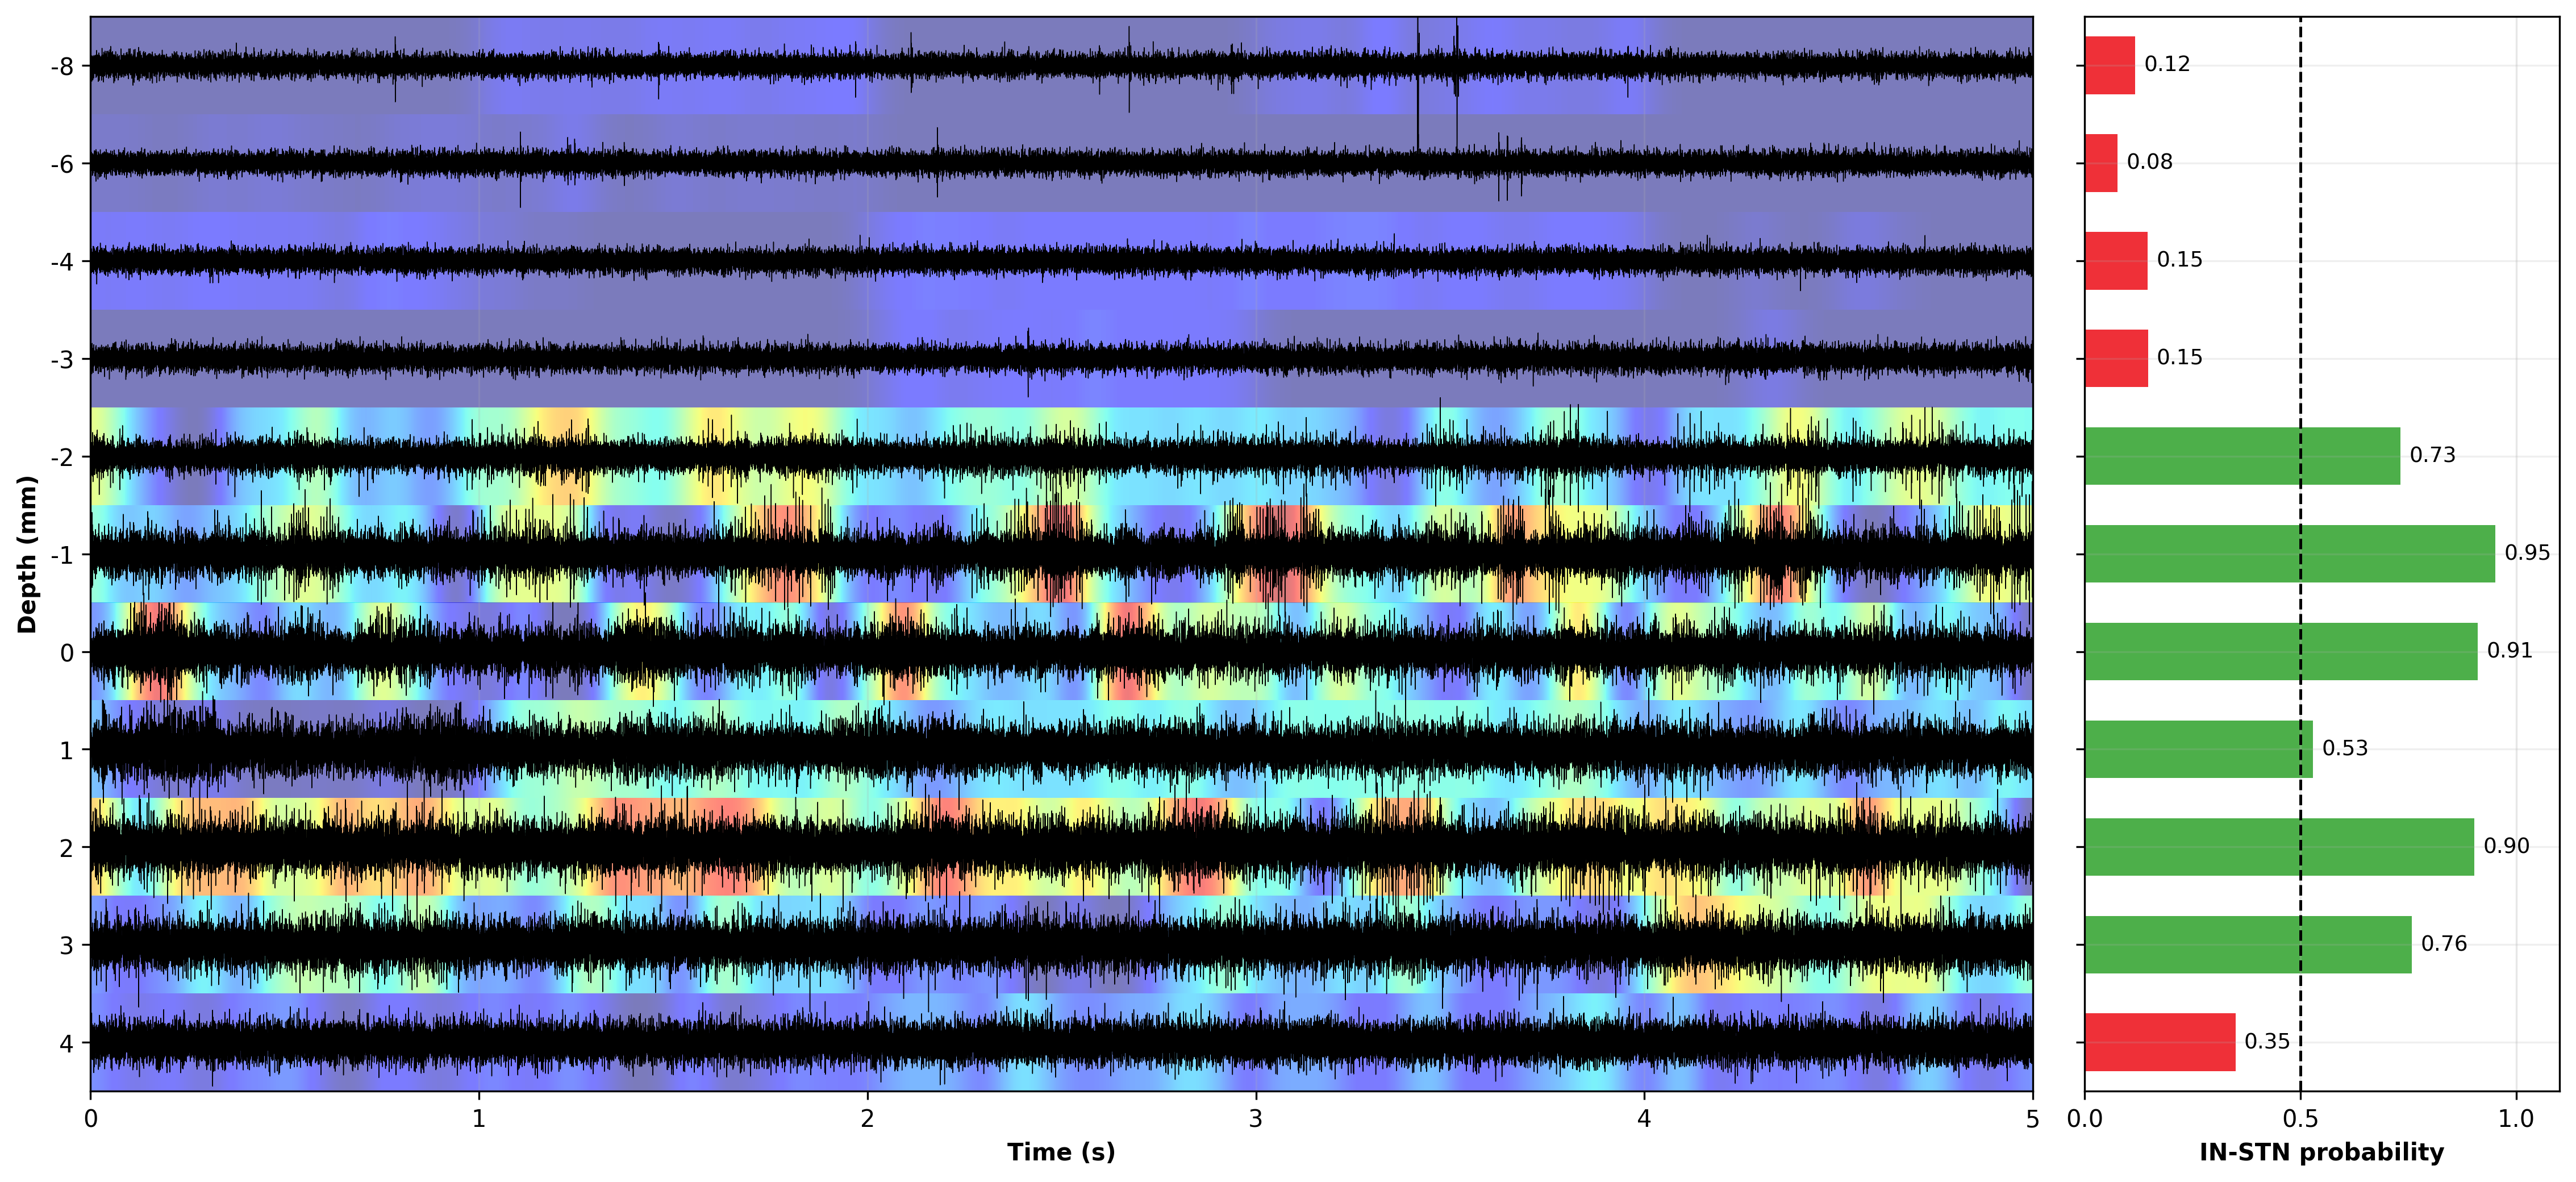

Generated explanations with shape (11, 50000).


In [6]:
relevance_maps, trace_probabilities = gradcam1D(
    resampled,
    TARGET_FS,
    model_path=MODELS / 'all_in_one.pt',
    target_class=1,
    return_probabilities=True,
)
gradcam_figure = plot_gradcam(
    resampled,
    relevance_maps,
    trace_probabilities,
    sampling_frequency=TARGET_FS,
    metadata=metadata,
    output_path=FIGURES / '04_gradcam.png',
)
plt.show()
print(f'Generated explanations with shape {relevance_maps.shape}.')

## Outputs

A complete run writes the raw trajectory, processed trajectory, probability-by-depth distribution, and Grad-CAM explanation figures to `results/main_figures/`. The in-memory `prediction_table` contains the metadata, class probabilities, and predicted class for every one-second window.